# Questão 13: Transformer passo a passo com a frase "o gato sentou no tapete"

**Dupla:** Bruno Gomes de Barros Filho (21111360); Antônio Rodrigo Lima de Andrade Tenório (23210707)
ECOM031: Inteligência Artificial. Prof. Evandro de Barros Costa. 2026.2

Este notebook acompanha o ensaio `docs/q13_transformers.md`. A primeira parte passa a frase
"o gato sentou no tapete" por um bloco decoder-only com pesos aleatórios (semente 0) e mostra
cada matriz intermediária. A segunda parte mede o efeito do fator $1/\sqrt{d_k}$ na softmax.
A terceira treina um modelo de uma camada só de atenção num corpus de brinquedo e verifica
para onde a atenção passa a olhar.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap

import transformer_numpy as tf
import treino as T

np.set_printoptions(precision=2, suppress=True, linewidth=120)
pd.set_option("display.float_format", "{:.2f}".format)
FIG = Path("figures")
FIG.mkdir(exist_ok=True)

AZUL, LARANJA, CINZA = "#2a78d6", "#eb6834", "#898781"
SEQ = LinearSegmentedColormap.from_list(
    "seq", ["#fcfcfb", "#cde2fb", "#86b6ef", "#2a78d6", "#184f95", "#0d366b"])
DIV = LinearSegmentedColormap.from_list("div", [AZUL, "#e1e0d9", LARANJA])
SEQ.set_bad("#e1e0d9")
DIV.set_bad("#e1e0d9")
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight", "figure.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.titlecolor": "#0b0b0b", "font.size": 10, "axes.grid": False, "grid.color": "#e1e0d9",
})


def heatmap(ax, M, rows, cols, title, vmin=0.0, vmax=1.0, cmap=SEQ):
    """Mapa de calor com o valor escrito em cada célula; -inf aparece como célula cinza."""
    show = np.where(np.isfinite(M), M, np.nan)
    ax.imshow(show, cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set_xticks(range(len(cols)), cols, rotation=45, ha="right")
    ax.set_yticks(range(len(rows)), rows)
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            v = M[i, j]
            if not np.isfinite(v):
                ax.text(j, i, "−∞", ha="center", va="center", fontsize=8, color="#52514e")
                continue
            claro = abs(v - (vmin + vmax) / 2) / (vmax - vmin) > 0.3 if cmap is DIV else (v - vmin) / (vmax - vmin) > 0.55
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8,
                    color="white" if claro else "#0b0b0b")
    ax.set_title(title, fontsize=10, loc="left")
    for s in ax.spines.values():
        s.set_visible(False)


def df(M, rows, cols):
    return pd.DataFrame(M, index=rows, columns=cols)

## 1. Tokenização

O vocabulário é o do corpus de brinquedo da Parte 3 (22 palavras), com tokenização por
espaço. Modelos reais usam subpalavras (BPE, WordPiece), mas a ideia é a mesma: o texto vira
uma lista de inteiros.

In [2]:
vocab = T.vocab_do_corpus()
frase = "o gato sentou no tapete"
toks = frase.split()
ids = tf.encode(frase, vocab)
print(len(vocab), "tokens no vocabulário:", vocab)
print("ids:", ids)

22 tokens no vocabulário: ['o', 'gato', 'sentou', 'no', 'tapete', 'e', 'depois', 'ele', 'dormiu', 'saiu', 'sofá', 'na', 'cadeira', 'cama', 'deitou', 'a', 'gata', 'ela', 'cachorro', 'cadela', 'menino', 'menina']
ids: [0 1 2 3 4]


## 2. Embeddings e codificação posicional

Modelo da demonstração: $d_{model}=8$, 2 cabeças com $d_k=4$, FFN com 32 neurônios, pesos
aleatórios com semente 0. A matriz de embeddings $E$ (22 × 8) também é usada na saída
(pesos amarrados, como no artigo original).

In [3]:
p = tf.init_params(len(vocab), d_model=8, n_heads=2, d_ff=32, seed=0)
logits, probs, tr = tf.forward(ids, p)
dims = [f"d{i}" for i in range(8)]
print("Embeddings E[ids]:")
display(df(tr["emb"], toks, dims))
print("Codificação posicional senoidal PE (5 × 8):")
display(df(tr["pe"], [f"pos {i}" for i in range(5)], dims))
print("Entrada do bloco x0 = E[ids] + PE:")
display(df(tr["x0"], toks, dims))

Embeddings E[ids]:


,d0,d1,d2,d3,d4,d5,d6,d7
o,0.13,-0.13,0.64,0.10,-0.54,0.36,1.30,0.95
gato,-0.70,-1.27,-0.62,0.04,-2.33,-0.22,-1.25,-0.73
sentou,-0.54,-0.32,0.41,1.04,-0.13,1.37,-0.67,0.35
no,0.90,0.09,-0.74,-0.92,-0.46,0.22,-1.01,-0.21
tapete,-0.16,0.54,0.21,0.36,-0.65,-0.13,0.78,1.49


Codificação posicional senoidal PE (5 × 8):


,d0,d1,d2,d3,d4,d5,d6,d7
pos 0,0.00,1.00,0.00,1.00,0.00,1.00,0.00,1.00
pos 1,0.84,0.54,0.10,1.00,0.01,1.00,0.00,1.00
pos 2,0.91,-0.42,0.20,0.98,0.02,1.00,0.00,1.00
pos 3,0.14,-0.99,0.30,0.96,0.03,1.00,0.00,1.00
pos 4,-0.76,-0.65,0.39,0.92,0.04,1.00,0.00,1.00


Entrada do bloco x0 = E[ids] + PE:


,d0,d1,d2,d3,d4,d5,d6,d7
o,0.13,0.87,0.64,1.10,-0.54,1.36,1.30,1.95
gato,0.14,-0.73,-0.52,1.04,-2.32,0.78,-1.24,0.27
sentou,0.37,-0.73,0.61,2.02,-0.11,2.37,-0.66,1.35
no,1.04,-0.90,-0.45,0.03,-0.43,1.22,-1.01,0.79
tapete,-0.92,-0.11,0.60,1.28,-0.61,0.87,0.79,2.49


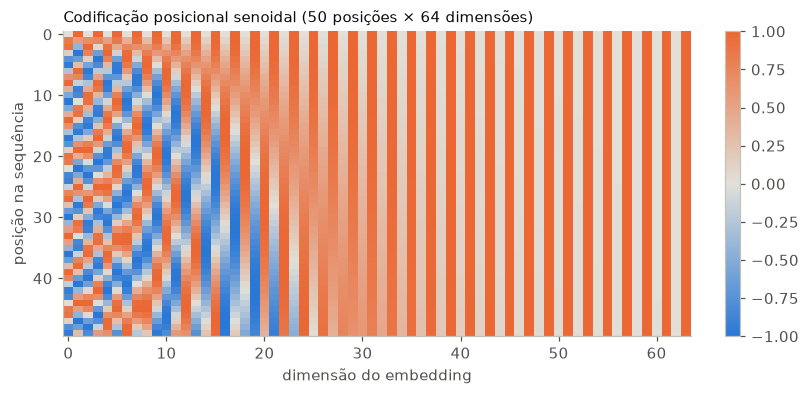

In [4]:
pe = tf.positional_encoding(50, 64)
fig, ax = plt.subplots(figsize=(8, 3.6))
im = ax.imshow(pe, cmap=DIV, vmin=-1, vmax=1, aspect="auto")
ax.set_xlabel("dimensão do embedding")
ax.set_ylabel("posição na sequência")
ax.set_title("Codificação posicional senoidal (50 posições × 64 dimensões)", loc="left", fontsize=10)
fig.colorbar(im, ax=ax, fraction=0.03)
fig.savefig(FIG / "q13_codificacao_posicional.png")
plt.show()

## 3. Q, K e V da cabeça 1

$Q = x_0 W_Q$, $K = x_0 W_K$, $V = x_0 W_V$; cada matriz 5 × 8 é dividida em 2 cabeças de 5 × 4.

In [5]:
dk_cols = [f"c{i}" for i in range(4)]
for nome in ["Q", "K", "V"]:
    print(f"{nome} (cabeça 1):")
    display(df(tr[nome][0], toks, dk_cols))

Q (cabeça 1):


,c0,c1,c2,c3
o,0.47,1.15,-1.77,1.23
gato,0.31,-2.03,-1.42,-1.49
sentou,0.39,-0.53,-2.90,2.43
no,-0.00,-0.27,-1.64,-0.08
tapete,1.45,0.67,-1.26,0.06


K (cabeça 1):


,c0,c1,c2,c3
o,-0.33,0.56,-1.66,0.09
gato,1.29,1.24,1.05,0.07
sentou,0.52,0.57,-1.03,0.61
no,1.15,0.11,0.49,-0.02
tapete,-0.68,1.19,-2.03,0.75


V (cabeça 1):


,c0,c1,c2,c3
o,-0.81,-0.09,1.19,-0.47
gato,-0.63,1.34,-1.55,0.69
sentou,-0.95,-0.04,-0.41,-1.26
no,-0.75,0.84,-0.73,-0.19
tapete,-1.50,1.11,0.83,-0.40


## 4. Scores, máscara causal e pesos de atenção

$\text{scores} = QK^T/\sqrt{d_k}$ com $\sqrt{4}=2$. A máscara põe $-\infty$ acima da diagonal
(o token $i$ não vê os tokens $j>i$) e a softmax de cada linha transforma o que sobra em pesos.

In [6]:
S = tr["scores"][0]
mask = tf.causal_mask(5)
S_mask = np.where(mask, -np.inf, S)
W = tr["weights"][0]
print("Scores QK^T/sqrt(d_k):"); display(df(S, toks, toks))
print("Máscara causal (True = bloqueado):"); display(df(mask, toks, toks))
print("Pesos de atenção (softmax por linha):"); display(df(W, toks, toks))
print("Soma de cada linha:", W.sum(1))

Scores QK^T/sqrt(d_k):


,o,gato,sentou,no,tapete
o,1.76,0.12,1.74,-0.12,2.78
gato,0.49,-1.86,-0.22,-0.26,-0.43
sentou,2.29,-1.53,2.19,-0.55,3.42
no,1.28,-1.04,0.74,-0.42,1.47
tapete,1.00,0.68,1.24,0.56,1.21


Máscara causal (True = bloqueado):


,o,gato,sentou,no,tapete
o,False,True,True,True,True
gato,False,False,True,True,True
sentou,False,False,False,True,True
no,False,False,False,False,True
tapete,False,False,False,False,False


Pesos de atenção (softmax por linha):


,o,gato,sentou,no,tapete
o,1.00,0.00,0.00,0.00,0.00
gato,0.91,0.09,0.00,0.00,0.00
sentou,0.52,0.01,0.47,0.00,0.00
no,0.54,0.05,0.31,0.10,0.00
tapete,0.21,0.15,0.26,0.13,0.25


Soma de cada linha: [1. 1. 1. 1. 1.]


In [7]:
# Conta à mão da linha de "tapete" (posição 4, enxerga as 5 posições)
q4, K0 = tr["Q"][0][4], tr["K"][0]
s = K0 @ q4 / np.sqrt(4)
e = np.exp(s - s.max())
print("produtos q·k / 2 :", s)
print("exp(s - max)     :", e)
print("pesos = e/soma   :", e / e.sum())
print("saída = pesos @ V:", (e / e.sum()) @ tr["V"][0])
print("saída do código  :", tr["heads"][0][4])

produtos q·k / 2 : [1.   0.68 1.24 0.56 1.21]
exp(s - max)     : [0.79 0.58 1.   0.51 0.97]
pesos = e/soma   : [0.21 0.15 0.26 0.13 0.25]
saída = pesos @ V: [-0.98  0.57  0.02 -0.45]
saída do código  : [-0.98  0.57  0.02 -0.45]


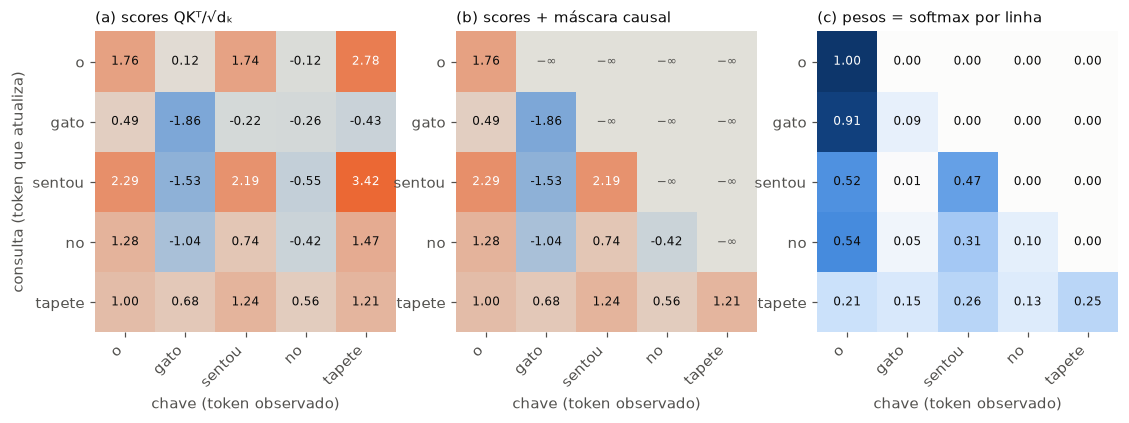

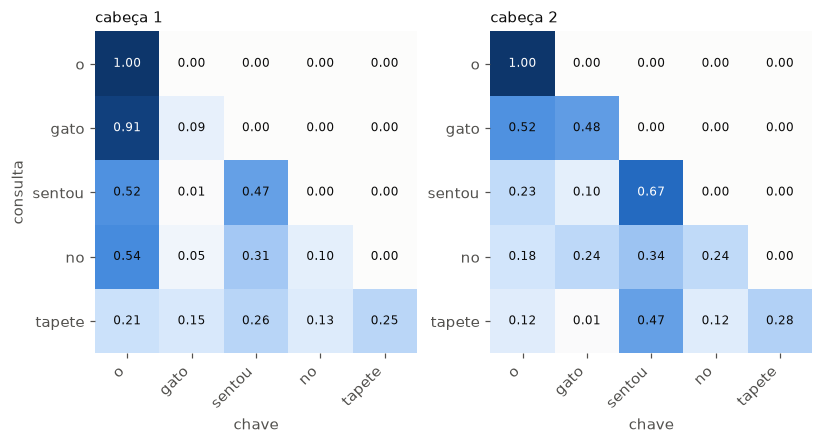

In [8]:
fig, axs = plt.subplots(1, 3, figsize=(12, 3.8))
lim = np.abs(S).max()
heatmap(axs[0], S, toks, toks, "(a) scores QKᵀ/√dₖ", -lim, lim, DIV)
heatmap(axs[1], S_mask, toks, toks, "(b) scores + máscara causal", -lim, lim, DIV)
heatmap(axs[2], W, toks, toks, "(c) pesos = softmax por linha")
for a in axs:
    a.set_xlabel("chave (token observado)")
axs[0].set_ylabel("consulta (token que atualiza)")
fig.savefig(FIG / "q13_scores_mascara_softmax.png")
plt.show()

fig, axs = plt.subplots(1, 2, figsize=(8.5, 3.8))
for h in range(2):
    heatmap(axs[h], tr["weights"][h], toks, toks, f"cabeça {h + 1}")
    axs[h].set_xlabel("chave")
axs[0].set_ylabel("consulta")
fig.savefig(FIG / "q13_pesos_duas_cabecas.png")
plt.show()

## 5. Do resultado da atenção à saída do bloco

Concatenação das cabeças, projeção $W_O$, soma residual, LayerNorm, FFN, nova soma residual e
nova LayerNorm (bloco pós-LN, como em Vaswani et al., 2017).

In [9]:
print("Saída da cabeça 1 (pesos @ V):"); display(df(tr["heads"][0], toks, dk_cols))
print("Concatenação das 2 cabeças (5 × 8):"); display(df(tr["concat"], toks, dims))
print("Após W_O:"); display(df(tr["attn_out"], toks, dims))
print("x1 = LayerNorm(x0 + atenção):"); display(df(tr["x1"], toks, dims))
print("média e desvio de cada linha de x1:", tr["x1"].mean(1).round(3), tr["x1"].std(1).round(3))
print("FFN(x1):"); display(df(tr["ffn_out"], toks, dims))
print("x2 = LayerNorm(x1 + FFN):"); display(df(tr["x2"], toks, dims))

Saída da cabeça 1 (pesos @ V):


,c0,c1,c2,c3
o,-0.81,-0.09,1.19,-0.47
gato,-0.80,0.03,0.95,-0.36
sentou,-0.87,-0.05,0.41,-0.83
no,-0.84,0.09,0.35,-0.63
tapete,-0.98,0.57,0.02,-0.45


Concatenação das 2 cabeças (5 × 8):


,d0,d1,d2,d3,d4,d5,d6,d7
o,-0.81,-0.09,1.19,-0.47,0.50,-0.50,-0.60,0.90
gato,-0.80,0.03,0.95,-0.36,1.06,-0.34,-1.13,0.27
sentou,-0.87,-0.05,0.41,-0.83,1.64,-0.18,-0.93,0.56
no,-0.84,0.09,0.35,-0.63,1.40,-0.12,-1.08,0.25
tapete,-0.98,0.57,0.02,-0.45,1.26,-0.32,-0.67,0.42


Após W_O:


,d0,d1,d2,d3,d4,d5,d6,d7
o,0.66,-0.56,-1.45,-0.04,-0.38,0.08,0.95,-0.16
gato,0.27,-0.45,-1.56,0.61,-0.53,-0.07,-0.06,0.40
sentou,0.54,-0.16,-1.81,1.16,-0.88,0.06,-0.21,0.56
no,0.40,-0.19,-1.54,1.10,-0.72,-0.19,-0.45,0.62
tapete,0.78,-0.04,-1.23,1.18,-0.79,-0.31,-0.23,0.59


... (2 outputs left out)

média e desvio de cada linha de x1: [ 0.  0. -0. -0.  0.] [1. 1. 1. 1. 1.]
FFN(x1):


,d0,d1,d2,d3,d4,d5,d6,d7
o,-0.55,0.24,0.00,-0.10,-0.64,0.07,-0.71,-0.36
gato,-0.62,-0.19,0.16,-0.65,-0.76,0.38,-0.32,-0.88
sentou,-0.71,-0.34,0.01,-0.52,-0.97,0.42,-0.07,-0.97
no,-0.38,-0.59,-0.14,-0.73,-1.32,0.54,0.11,-0.96
tapete,-1.03,-0.27,-0.06,-0.86,-0.70,1.00,-0.00,-1.28


x2 = LayerNorm(x1 + FFN):


,d0,d1,d2,d3,d4,d5,d6,d7
o,-0.25,0.09,-1.18,0.46,-1.92,0.98,0.95,0.87
gato,0.34,-0.27,-0.54,1.12,-1.92,1.50,-0.49,0.26
sentou,-0.10,-0.75,-0.60,1.33,-1.37,1.77,-0.50,0.22
no,1.03,-0.79,-0.98,0.53,-1.47,1.58,-0.40,0.50
tapete,-1.10,-0.35,-0.48,0.88,-1.65,1.40,0.41,0.90


## 6. Projeção para o vocabulário e softmax

$\text{logits} = x_2 E^T$ (5 × 22). Cada linha é a distribuição da próxima palavra naquela
posição. Com pesos aleatórios a distribuição não tem significado linguístico; a Parte 3 mostra o
que muda depois do treino.

In [10]:
for i, t in enumerate(toks):
    top = np.argsort(probs[i])[::-1][:3]
    print(f"após '{t}':", ", ".join(f"{vocab[j]} {probs[i, j]:.3f}" for j in top))
print("soma das probabilidades de cada posição:", probs.sum(1))
print("probabilidade uniforme seria 1/22 =", round(1 / 22, 3))

após 'o': cama 0.314, sofá 0.199, cachorro 0.179
após 'gato': cama 0.756, gato 0.113, cachorro 0.061
após 'sentou': cama 0.584, gato 0.130, sentou 0.098
após 'no': cama 0.731, cachorro 0.136, gato 0.035
após 'tapete': cama 0.255, gato 0.144, gata 0.142
soma das probabilidades de cada posição: [1. 1. 1. 1. 1.]
probabilidade uniforme seria 1/22 = 0.045


## 7. Por que o KV cache funciona

Com a máscara causal, acrescentar um token no fim não muda as representações das posições
anteriores. Por isso, na geração, K e V do prefixo podem ser guardados e só a linha nova
precisa ser calculada (ligação com a Q5).

In [11]:
_, _, tr_pref = tf.forward(ids[:4], p)              # "o gato sentou no"
print("saídas do prefixo inalteradas:", np.allclose(tr_pref["x2"], tr["x2"][:4]))

def split(m):
    return m.reshape(1, 2, 4).transpose(1, 0, 2)

x_novo = tr["x0"][4:5]                               # só "tapete"
q, k, v = split(x_novo @ p["Wq"]), split(x_novo @ p["Wk"]), split(x_novo @ p["Wv"])
K_cache = np.concatenate([tr_pref["K"], k], axis=1)  # 4 linhas guardadas + 1 nova
V_cache = np.concatenate([tr_pref["V"], v], axis=1)
out_inc, _, _ = tf.attention(q, K_cache, V_cache)
print("atenção incremental == atenção completa:", np.allclose(out_inc[:, 0], tr["heads"][:, 4]))

saídas do prefixo inalteradas: True
atenção incremental == atenção completa: True


## 8. Sem posição, a atenção não vê ordem

Sem codificação posicional e sem máscara, permutar os tokens de entrada apenas permuta as
saídas (equivariância). Com a codificação posicional isso deixa de valer.

In [12]:
perm = np.array([4, 2, 0, 3, 1])                     # "tapete sentou o no gato"
x = tr["emb"]
y, _ = tf.decoder_block(x, p)
y_perm, _ = tf.decoder_block(x[perm], p)
print("sem PE: bloco(x[perm]) == bloco(x)[perm] ->", np.allclose(y_perm, y[perm]))
xp = x + tf.positional_encoding(5, 8)
y2, _ = tf.decoder_block(xp, p)
y2_perm, _ = tf.decoder_block(x[perm] + tf.positional_encoding(5, 8), p)
print("com PE: bloco(x[perm]+PE) == bloco(x+PE)[perm] ->", np.allclose(y2_perm, y2[perm]))

sem PE: bloco(x[perm]) == bloco(x)[perm] -> True
com PE: bloco(x[perm]+PE) == bloco(x+PE)[perm] -> False


## 9. O efeito de $\sqrt{d_k}$ na saturação da softmax

Sorteamos $q$ e 8 chaves $k$ com componentes $\mathcal{N}(0,1)$. O produto $q\cdot k$ tem
variância $d_k$; sem a divisão por $\sqrt{d_k}$ a softmax concentra quase todo o peso numa chave
e o gradiente some. A norma do jacobiano da softmax ($\text{diag}(w) - ww^T$) mede quanto
gradiente passa.

In [13]:
rng = np.random.default_rng(0)
dks, n_chaves, tentativas = [4, 16, 64, 256, 1024], 8, 2000
linhas = []
for dk in dks:
    q = rng.normal(size=(tentativas, 1, dk))
    k = rng.normal(size=(tentativas, n_chaves, dk))
    s = (q @ k.transpose(0, 2, 1))[:, 0]
    for nome, ss in [("sem escala", s), ("com escala", s / np.sqrt(dk))]:
        w = tf.softmax(ss)
        J = w[:, :, None] * np.eye(n_chaves) - w[:, :, None] * w[:, None, :]
        linhas.append({"d_k": dk, "escala": nome, "desvio dos scores": ss.std(),
                       "peso máximo médio": w.max(1).mean(),
                       "entropia média": -(w * np.log(w + 1e-12)).sum(1).mean(),
                       "norma do jacobiano": np.linalg.norm(J, axis=(1, 2)).mean()})
exp_dk = pd.DataFrame(linhas)
print("entropia máxima possível (8 chaves) = ln 8 =", round(np.log(8), 3))
display(exp_dk.pivot(index="d_k", columns="escala"))

entropia máxima possível (8 chaves) = ln 8 = 2.079


desvio dos scores            peso máximo médio             \
escala        com escala sem escala        com escala sem escala   
d_k                                                                
4                   1.00       2.00              0.34       0.52   
16                  1.01       4.03              0.36       0.75   
64                  1.00       8.01              0.36       0.87   
256                 0.99      15.87              0.36       0.94   
1024                1.00      31.85              0.36       0.97   

       entropia média            norma do jacobiano             
escala     com escala sem escala         com escala sem escala  
d_k                                                             
4                1.75       1.29               0.36       0.34  
16               1.73       0.67               0.36       0.25  
64               1.73       0.32               0.37       0.15  
256              1.73       0.15               0.37       0.08  
1024             1.72       0.08               0.37       0.04

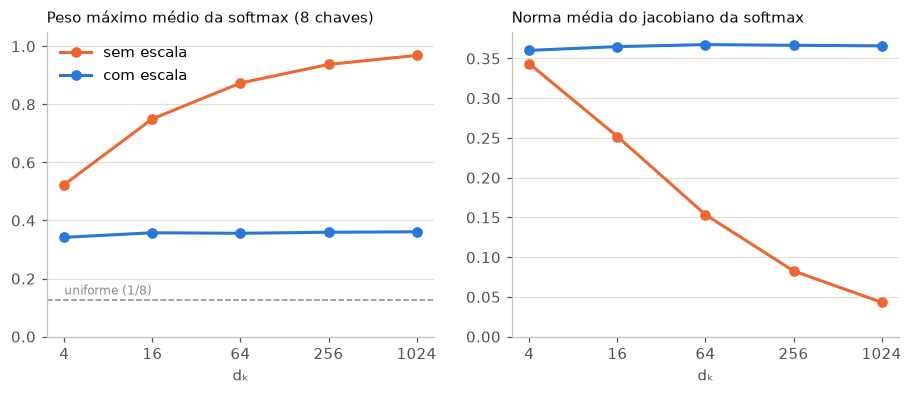

In [14]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3.6))
for nome, cor in [("sem escala", LARANJA), ("com escala", AZUL)]:
    sub = exp_dk[exp_dk.escala == nome]
    axs[0].plot(sub.d_k, sub["peso máximo médio"], "-o", color=cor, lw=2, ms=6, label=nome)
    axs[1].plot(sub.d_k, sub["norma do jacobiano"], "-o", color=cor, lw=2, ms=6, label=nome)
for a in axs:
    a.set_xscale("log", base=2)
    a.set_xticks(dks, [str(d) for d in dks])
    a.set_xlabel("dₖ")
    a.grid(axis="y")
axs[0].axhline(1 / 8, color=CINZA, lw=1, ls="--")
axs[0].text(4, 1 / 8 + 0.02, "uniforme (1/8)", color=CINZA, fontsize=8)
axs[0].set_title("Peso máximo médio da softmax (8 chaves)", loc="left", fontsize=10)
axs[1].set_title("Norma média do jacobiano da softmax", loc="left", fontsize=10)
axs[0].set_ylim(0, 1.05)
axs[1].set_ylim(0, None)
axs[0].legend(frameon=False)
fig.savefig(FIG / "q13_escala_raiz_dk.png")
plt.show()

## 10. Treino minúsculo: a atenção aprende a achar o sujeito

Corpus com 96 frases do tipo "o gato sentou no tapete e depois ele dormiu"
(6 sujeitos × 2 verbos × 4 lugares × 2 finais). Para prever "ele"/"ela" depois de "depois",
o modelo precisa olhar para o sujeito, e o "no/na" + lugar, que também têm gênero, são
distratores mais próximos. Modelo: uma camada, uma cabeça, $d=16$, só atenção + residual
(sem FFN e sem LayerNorm), gradiente escrito à mão em `treino.py` e conferido por diferenças
finitas nos testes. Adam, 1500 passos em lote completo, 72 frases de treino e 24 de teste.

In [15]:
treino, teste = T.split_corpus(T.corpus())
Xtr = np.array([tf.encode(s, vocab) for s in treino])
Xte = np.array([tf.encode(s, vocab) for s in teste])
frase_longa = "o gato sentou no tapete e depois ele dormiu"
toks_l = frase_longa.split()
ids_l = tf.encode(frase_longa, vocab)[None]
print(len(treino), "frases de treino,", len(teste), "de teste")
print("frase de exemplo está no", "treino" if frase_longa in treino else "teste")

pm = T.init(len(vocab), d=16, seed=0)
A_antes = T.forward(ids_l, pm)[1][5][0]
print("antes:  acurácia do pronome treino/teste =", T.pronoun_accuracy(Xtr, pm), T.pronoun_accuracy(Xte, pm))
perdas = T.train(Xtr, pm, steps=1500, lr=0.01)
A_depois = T.forward(ids_l, pm)[1][5][0]
print("depois: acurácia do pronome treino/teste =", T.pronoun_accuracy(Xtr, pm), T.pronoun_accuracy(Xte, pm))
perda_teste = T.loss_and_grads(Xte, pm)[0]
minimo = (np.log(3) + 4 * np.log(2)) / 8
print(f"perda inicial {perdas[0]:.3f}, final treino {perdas[-1]:.3f}, teste {perda_teste:.3f}, mínimo teórico {minimo:.3f}")

72 frases de treino, 24 de teste
frase de exemplo está no treino
antes:  acurácia do pronome treino/teste = 0.5 0.5


depois: acurácia do pronome treino/teste = 1.0 1.0
perda inicial 4.159, final treino 0.463, teste 0.825, mínimo teórico 0.484


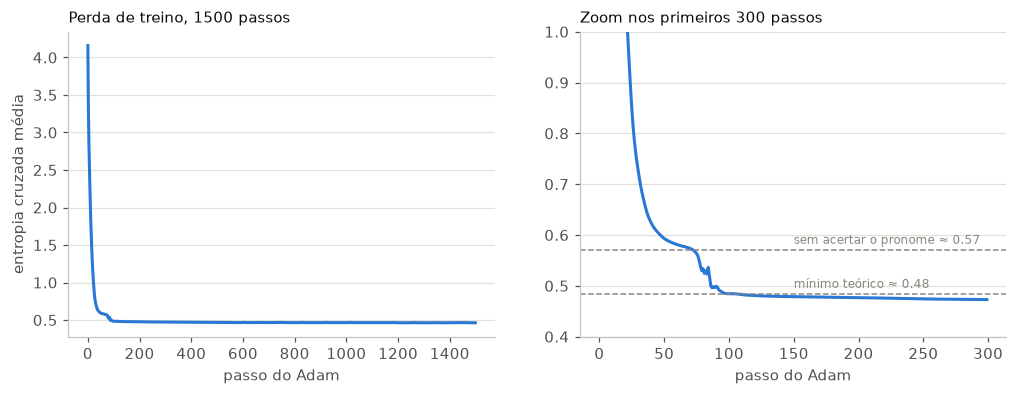

In [16]:
sem_pronome = minimo + np.log(2) / 8   # perda de quem chuta ele/ela com 50%
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
axs[0].plot(perdas, color=AZUL, lw=2)
axs[0].set_title("Perda de treino, 1500 passos", loc="left", fontsize=10)
axs[1].plot(range(300), perdas[:300], color=AZUL, lw=2)
axs[1].set_ylim(0.4, 1.0)
axs[1].set_title("Zoom nos primeiros 300 passos", loc="left", fontsize=10)
for y, txt in [(minimo, f"mínimo teórico ≈ {minimo:.2f}"), (sem_pronome, f"sem acertar o pronome ≈ {sem_pronome:.2f}")]:
    axs[1].axhline(y, color=CINZA, lw=1, ls="--")
    axs[1].text(150, y + 0.012, txt, color=CINZA, fontsize=8)
for a in axs:
    a.set_xlabel("passo do Adam")
    a.grid(axis="y")
axs[0].set_ylabel("entropia cruzada média")
fig.savefig(FIG / "q13_treino_perda.png")
plt.show()

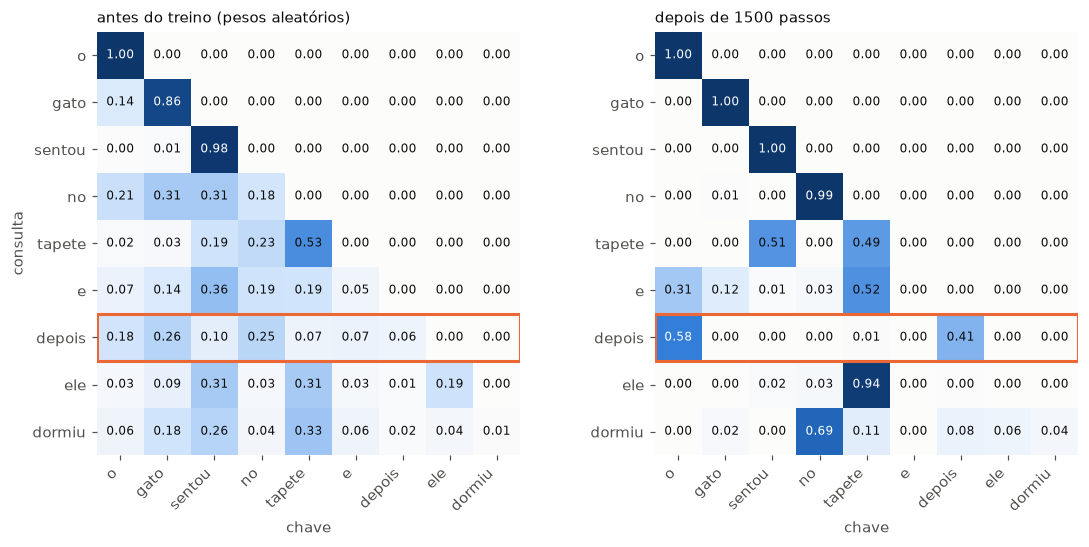

linha de 'depois' antes : [0.18 0.26 0.1  0.25 0.07 0.07 0.06]
linha de 'depois' depois: [0.58 0.   0.   0.   0.01 0.   0.41]


In [17]:
fig, axs = plt.subplots(1, 2, figsize=(12, 5))
heatmap(axs[0], A_antes, toks_l, toks_l, "antes do treino (pesos aleatórios)")
heatmap(axs[1], A_depois, toks_l, toks_l, "depois de 1500 passos")
for a in axs:
    a.set_xlabel("chave")
    a.add_patch(plt.Rectangle((-0.5, 5.5), 9, 1, fill=False, ec=LARANJA, lw=2))
axs[0].set_ylabel("consulta")
fig.savefig(FIG / "q13_atencao_antes_depois.png")
plt.show()
print("linha de 'depois' antes :", A_antes[6, :7])
print("linha de 'depois' depois:", A_depois[6, :7])

In [18]:
logits_te, _ = T.forward(Xte, pm)
p_dep = tf.softmax(logits_te[:, T.POS_DEPOIS])
i_ele, i_ela = vocab.index("ele"), vocab.index("ela")
tab = pd.DataFrame({"frase de teste": teste, "P(ele)": p_dep[:, i_ele], "P(ela)": p_dep[:, i_ela],
                    "previsto": [vocab[j] for j in p_dep.argmax(1)]})
display(tab)

,frase de teste,P(ele),P(ela),previsto
0,a menina deitou na cadeira e depois ela dormiu,0.00,1.00,ela
1,o cachorro deitou na cama e depois ele dormiu,1.00,0.00,ele
2,a cadela deitou no sofá e depois ela dormiu,0.00,1.00,ela
3,o gato deitou na cama e depois ele dormiu,1.00,0.00,ele
4,o menino deitou no tapete e depois ele saiu,1.00,0.00,ele
5,o cachorro sentou na cama e depois ele dormiu,1.00,0.00,ele
6,a menina sentou na cadeira e depois ela dormiu,0.00,1.00,ela
7,a gata deitou na cama e depois ela saiu,0.00,1.00,ela
8,a menina sentou na cadeira e depois ela saiu,0.00,1.00,ela
9,a cadela sentou no tapete e depois ela dormiu,0.00,1.00,ela


In [19]:
for prompt in ["a cadela deitou no sofá e depois", "o menino sentou na cama e depois", "a menina"]:
    out = T.generate(tf.encode(prompt, vocab), pm, 9 - len(prompt.split()))
    print(f"{prompt!r:40} -> {tf.decode(out, vocab)}")

'a cadela deitou no sofá e depois'       -> a cadela deitou no sofá e depois ela saiu
'o menino sentou na cama e depois'       -> o menino sentou na cama e depois ele dormiu
'a menina'                               -> a menina deitou no sofá e depois ela saiu


### 10.1 Repetindo com 10 sementes

O resultado depende da inicialização. A tabela e a figura mostram, para cada semente, a perda
final, a acurácia do pronome no teste e a distribuição média da atenção de "depois" sobre as
posições anteriores.

,perda final,acurácia teste,o/a,sujeito,verbo,no/na,lugar,e,depois
semente,,,,,,,,,
0,0.46,1.00,0.53,0.06,0.00,0.00,0.01,0.00,0.40
1,0.47,1.00,0.27,0.26,0.00,0.00,0.00,0.47,0.00
2,0.55,0.50,0.00,0.00,0.00,0.00,0.00,0.00,1.00
3,0.47,1.00,0.50,0.01,0.00,0.00,0.00,0.49,0.00
4,0.47,1.00,0.00,0.34,0.00,0.00,0.07,0.58,0.00
5,0.46,1.00,0.80,0.11,0.04,0.00,0.04,0.00,0.00
6,0.55,0.50,0.00,0.00,0.00,0.00,0.00,0.00,1.00
7,0.54,0.75,0.00,0.14,0.00,0.00,0.00,0.01,0.85
8,0.46,1.00,0.31,0.00,0.03,0.64,0.01,0.00,0.00


sementes com 100% no teste: 7 de 10


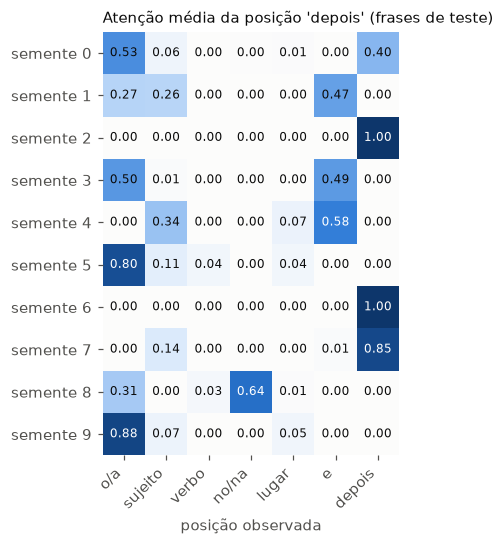

In [20]:
pos_cols = ["o/a", "sujeito", "verbo", "no/na", "lugar", "e", "depois"]
res, linhas_att = [], []
for seed in range(10):
    ps = T.init(len(vocab), d=16, seed=seed)
    L = T.train(Xtr, ps, steps=1500, lr=0.01)
    att = T.attention_from_depois(Xte, ps)
    linhas_att.append(att)
    res.append({"semente": seed, "perda final": L[-1], "acurácia teste": T.pronoun_accuracy(Xte, ps),
                **dict(zip(pos_cols, att))})
res = pd.DataFrame(res).set_index("semente")
display(res)
print("sementes com 100% no teste:", int((res["acurácia teste"] == 1).sum()), "de 10")

fig, ax = plt.subplots(figsize=(7, 5))
heatmap(ax, np.array(linhas_att), [f"semente {s}" for s in range(10)], pos_cols,
        "Atenção média da posição 'depois' (frases de teste)")
ax.set_xlabel("posição observada")
fig.savefig(FIG / "q13_atencao_sementes.png")
plt.show()